# Customer Support Analysis

**Team:** TwoSeven

**Member:** Lucas Liu, Weijun Fan, Shujun Chen

### Background
Many customers tweet a brand for help when their products go wrong. In late 2017, support teams faced two very different surges: Apple’s iOS 11.1 keyboard bug (released Oct 31, fixed Nov 9) and Amazon’s Black Friday (Nov 24) and Cyber Monday (Nov 27).

### Research Problem
1. Do the posting time and wording affect the response speed?
    - Morning or Night
    - Rude or Polite
2. How do support teams react to a planned peak vs an unplanned emergency?
    - Planned Black Friday vs iOS 11.1 keyboard bug
3. Which similar-case search method is more helpful?
    - keywords (TF-IDF) or semantic embeddings

### Delivery
We will deliver a system that accepts a customer's query about the products, and then provide the expected waiting time according to the user's words, posting time and whether it is a peak time, and provide a few related cases for user to review while they are waiting.

## Data Cleaning

### 1. Read Data

In [1]:
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from langdetect import detect, DetectorFactory # detect language
from tqdm import tqdm # show the data process time

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

random_seed = 42

W1123 18:04:44.536000 6524 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
df = pd.read_csv("./data/twcs/twcs.csv")
print("Data Shape: ", df.shape)
df.head()

Data Shape:  (2811774, 7)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0


There are 281,1774 data, each row is a tweet, contains 7 columns:
- `tweet_id`: The unique ID of the tweet.
- `author_id`: The ID or account name of the person or support team that posted the tweet.
- `inbound`: Whether the tweet was sent to a company. `True`: a customer message. `False`: a support message.
- `created_at`: The date and time when the tweet was posted.
- `text`: The text of the tweet.
- `response_tweet_id`: The ID(s) of tweets that replied to this tweet, if any.
- `in_response_to_tweet_id`: The ID of the tweet that this tweet replied to, if any.

### 2. Check Missing and Duplicate Data

In [3]:
# Calculate the missing data count
print("Missing Count:")
print(df.isnull().sum())

both_missing = df[df["response_tweet_id"].isnull() & df["in_response_to_tweet_id"].isnull()]
print("Tweets with both IDs missing:", both_missing.shape[0])

Missing Count:
tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64
Tweets with both IDs missing: 0


- Missing `response_tweet_id`: last tweet of a series of converstation.
- Missing `in_response_to_tweet_id`: start of a series of conversation.
- Both are missing: neither field records a reply link, so the tweet may be a standalone message.

Missing IDs do not tell us whether the author is a customer or a support account, `inbound` column tell us these.

In [4]:
print("Exact duplicate rows:", df.duplicated().sum())

id_counts = df["tweet_id"].value_counts()
print("Number of repeated tweet IDs:", (id_counts > 1).sum())

Exact duplicate rows: 0
Number of repeated tweet IDs: 0


### 3. Brand Statistics

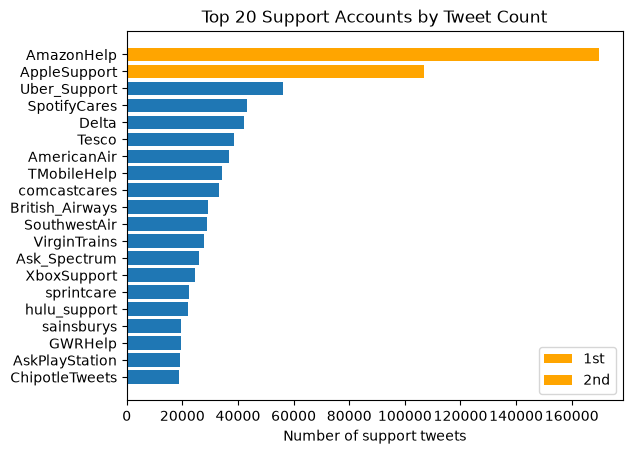

In [5]:
support_tweets = df[df["inbound"] == False]
brand_counts = pd.DataFrame({"Support Tweet Count": support_tweets["author_id"].value_counts()})
top_brands = brand_counts.head(20).sort_values("Support Tweet Count")

plt.barh(top_brands.index, top_brands["Support Tweet Count"])
plt.barh(top_brands.index[-1], top_brands["Support Tweet Count"].iloc[-1], color="orange", label="1st")
plt.barh(top_brands.index[-2], top_brands["Support Tweet Count"].iloc[-2], color="orange", label="2nd")
plt.xlabel("Number of support tweets")
plt.title("Top 20 Support Accounts by Tweet Count")
plt.legend()
plt.show()

The chart shows the 20 support accounts with the most tweets. 

AmazonHelp has the most support tweets, followed by AppleSupport. 
For the rest of this project, we will study only Amazon and Apple, including their support tweets and related customer messages.

Next, we need to assign the related brand to each tweet, then we can delete the other brands' tweets safely.

The Algorithm is:
- first assign those tweet from a support account.
- While there are still tweets without a related brand:
    - propagate the brand that newly assigned last iteration to its parent tweets and its replies.

In [6]:
def find_related_brands(data):
    """Fill unknown brands one reply step at a time using pandas.
    Keep the first assigned brand and return a Series aligned with data.
    """
    # First label the support tweet.
    messages = data[["tweet_id", "in_response_to_tweet_id"]].copy()
    messages["related_brand"] = data["author_id"].where(data["inbound"] == False)
    # Now, only support tweets have the label.
    # new_labels is the latest updated data every iteration.
    new_labels = messages[messages["related_brand"].notna()]
    # unknown is those who haven't been updated.
    unknown = messages[messages["related_brand"].isna()].copy()

    # Only newly labeled tweets need to pass their brand to unknown tweets.
    while not new_labels.empty and not unknown.empty:
        parent_brand = new_labels.set_index("tweet_id")["related_brand"]
        reply_brand = new_labels.groupby("in_response_to_tweet_id")["related_brand"].first()
        # Within each round, use the parent's brand before a reply's brand.
        unknown["related_brand"] = unknown["in_response_to_tweet_id"].map(parent_brand)
        unknown["related_brand"] = unknown["related_brand"].fillna(unknown["tweet_id"].map(reply_brand))
        new_labels = unknown[unknown["related_brand"].notna()]
        messages.loc[new_labels.index, "related_brand"] = new_labels["related_brand"]
        unknown = unknown[unknown["related_brand"].isna()].copy()

    return messages["related_brand"]

cleaned_df = df.copy()

# Add brand labels, then keep tweets related to Amazon or Apple.
cleaned_df["related_brand"] = find_related_brands(cleaned_df)
print("Tweets before filtering:", cleaned_df.shape[0])
cleaned_df = cleaned_df[cleaned_df["related_brand"].isin(["AmazonHelp", "AppleSupport"])]
print("Tweets after filtering:", cleaned_df.shape[0])
cleaned_df.head()

Tweets before filtering: 2811774
Tweets after filtering: 611145


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,related_brand
181,269,AmazonHelp,False,Wed Nov 22 09:23:01 +0000 2017,@115770 こんにちは、アマゾン公式です。Fire TV Stickが見れないというのは...,"270,271",272.0,AmazonHelp
182,270,115770,True,Wed Nov 22 09:24:30 +0000 2017,@AmazonHelp ありがとうございます。\n今、電話で主人が対応していただいてます。,NaN,269.0,AmazonHelp
183,271,115770,True,Wed Nov 22 09:30:36 +0000 2017,@AmazonHelp 電話で対応してもらいましたが改良されませんでした。\n保証期間も過ぎ...,273,269.0,AmazonHelp
184,273,AmazonHelp,False,Wed Nov 22 09:40:27 +0000 2017,@115770 カスタマーサービスにてお問い合わせ済みとのことで、お手数をおかけいたしました...,274,271.0,AmazonHelp
185,274,115770,True,Wed Nov 22 09:44:04 +0000 2017,@AmazonHelp こちらこそありがとうございました。,275,273.0,AmazonHelp


### 4. Check Data Types

In [7]:
print("Data Type:")
print(cleaned_df.dtypes)

Data Type:
tweet_id                     int64
author_id                      str
inbound                       bool
created_at                     str
text                           str
response_tweet_id              str
in_response_to_tweet_id    float64
related_brand                  str
dtype: object


- `tweet_id` is `int64`: it contains integer IDs with no missing values.
- `in_response_to_tweet_id` is `float64`: it contains missing values (`NaN`), which regular `int64` cannot store.
- `response_tweet_id` is `str`: some values contain several reply IDs separated by commas, such as `"5,7"`.
- `created_at` is `str`: it is a timestamp in the string form, which cannot do the subtracting calculation.

So, we turn `tweet_id` and `in_response_to_tweet_id` into `Int64`, turn `response_tweet_id` into a list of `int`, turn `created_at` into `datetime`.

In [8]:
# Convert the str into list
response_ids = []
for response in cleaned_df["response_tweet_id"].fillna(""):
    response_ids.append([int(x) for x in response.split(",") if x != ""])
cleaned_df["response_tweet_id"] = response_ids

# Change type to Int64 (can store NaN)
cleaned_df["tweet_id"] = cleaned_df["tweet_id"].astype("Int64")
cleaned_df["in_response_to_tweet_id"] = cleaned_df["in_response_to_tweet_id"].astype("Int64")

# Change type to datetime
cleaned_df["created_at"] = pd.to_datetime(cleaned_df["created_at"], format="%a %b %d %H:%M:%S %z %Y", utc=True)

print("Data Type:")
print(cleaned_df.dtypes)

Data Type:
tweet_id                                 Int64
author_id                                  str
inbound                                   bool
created_at                 datetime64[us, UTC]
text                                       str
response_tweet_id                       object
in_response_to_tweet_id                  Int64
related_brand                              str
dtype: object


### 5. Check Time Range

Earliest tweet: 2011-10-13 11:57:18+00:00
Latest tweet: 2017-12-03 23:13:02+00:00


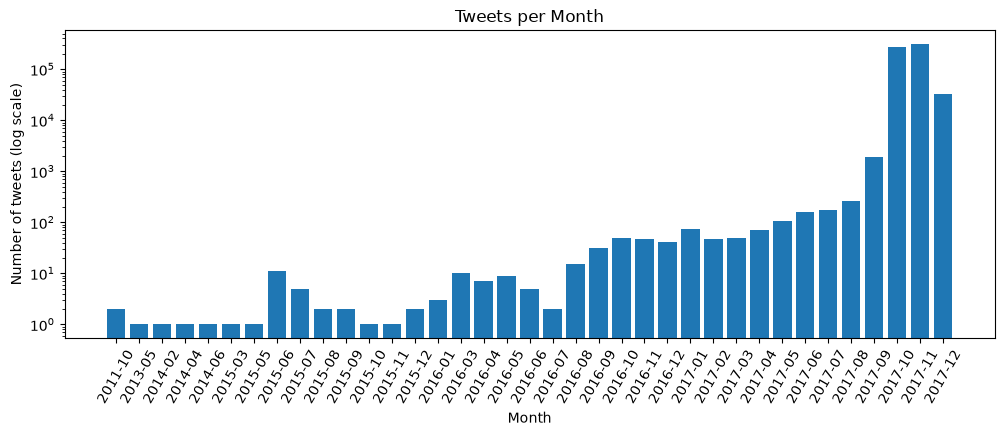

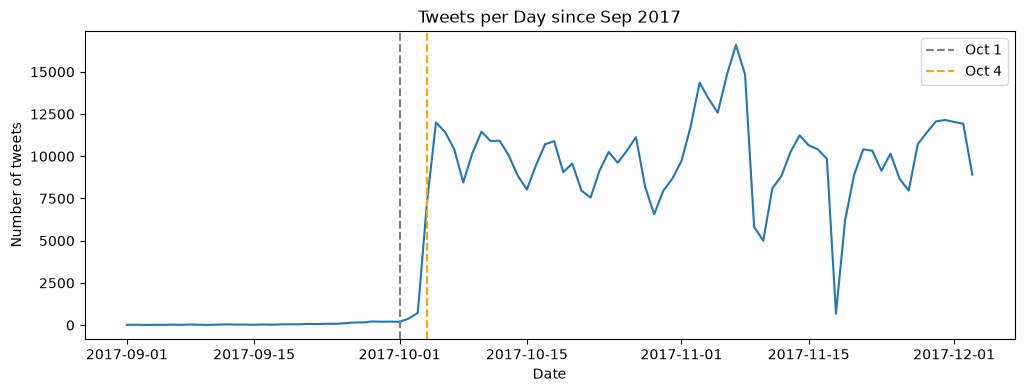

In [9]:
print("Earliest tweet:", cleaned_df["created_at"].min())
print("Latest tweet:", cleaned_df["created_at"].max())

# Count tweets per month (log scale, because early months are very small)
month_counts = pd.DataFrame({"Tweet Count": cleaned_df["created_at"].dt.strftime("%Y-%m").value_counts().sort_index()})

plt.figure(figsize=(12, 4))
plt.bar(month_counts.index, month_counts["Tweet Count"])
plt.yscale("log")
plt.xticks(rotation=60)
plt.xlabel("Month")
plt.ylabel("Number of tweets (log scale)")
plt.title("Tweets per Month")
plt.show()

# Zoom in: count tweets per day since Sep 2017
recent = cleaned_df[cleaned_df["created_at"] >= "2017-09-01"]
day_counts = recent["created_at"].dt.date.value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts.values)
plt.axvline(pd.Timestamp("2017-10-01"), color="gray", linestyle="--", label="Oct 1")
plt.axvline(pd.Timestamp("2017-10-04"), color="orange", linestyle="--", label="Oct 4")
plt.xlabel("Date")
plt.ylabel("Number of tweets")
plt.title("Tweets per Day since Sep 2017")
plt.legend()
plt.show()

Most tweets are from October to early December 2017. Before that, each month has only a few tweets.

- These early tweets are scattered. They were likely pulled in because later conversations replied to them.
- The daily count jumps from a few hundred to over 6,000 on Oct 4, 2017, so continuous data collection starts there.
- We keep tweets from Oct 4, 2017 onward and remove the earlier ones.
- Both events for RQ2 come after this date: the iOS 11.1 keyboard bug (Oct 31 - Nov 9) and Black Friday / Cyber Monday (Nov 24 - Nov 27). Oct 4 - Oct 30 can serve as a normal period for comparison.

In [10]:
print("Tweets before filtering:", cleaned_df.shape[0])
# Keep tweets from Oct 4, 2017
cleaned_df = cleaned_df[cleaned_df["created_at"] >= "2017-10-04"]
print("Tweets after filtering:", cleaned_df.shape[0])
print("Earliest tweet:", cleaned_df["created_at"].min())

Tweets before filtering: 611145
Tweets after filtering: 606758
Earliest tweet: 2017-10-04 00:00:00+00:00


### 6. Detect Language

Some tweets are not in English.
Our text analysis (rude or polite words, TF-IDF, embeddings) only works for English, so we check the language of each tweet.

We use the characters in the text to guess the language:
- Hiragana or Katakana: Japanese (`japan`)
- Hangul: Korean (`korean`)
- Chinese characters: Chinese (`china`)
- Latin letters only: English or other western languages (`latin`)
- None of the above: `other`

Mentions (`@xxx`) and links are removed first, because they are always in Latin letters.

In [11]:
text = cleaned_df["text"].str.replace(r"@\w+|https?://\S+", "", regex=True)

cleaned_df["language"] = np.select(
    [text.str.contains("[\u3040-\u30ff]"),
     text.str.contains("[\uac00-\ud7af]"),
     text.str.contains("[\u4e00-\u9fff]"),
     text.str.contains("[A-Za-z]")],
    ["japan", "korean", "china", "latin"],
    default="other"
)

Tweets with the `latin` tag still include many non-English languages (Spanish, French, ...). So we use the `langdetect` package. It is slow on a large dataset, so we only run it on `latin` tweets.

In [12]:
DetectorFactory.seed = random_seed

latin_text = text[cleaned_df["language"] == "latin"]
short = latin_text.str.split().str.len() <= 4

detected = []
for t in tqdm(latin_text[~short], desc="Detecting language"):
    try:
        detected.append(detect(t))
    except Exception:
        detected.append("unknown")

cleaned_df.loc[latin_text[short].index, "language"] = "en"
cleaned_df.loc[latin_text[~short].index, "language"] = detected

language_counts = pd.DataFrame({"Tweet Count": cleaned_df["language"].value_counts()})
language_counts.head()


Detecting language: 100%|██████████| 554279/554279 [06:16<00:00, 1470.94it/s]


,Tweet Count
language,
en,519059
japan,19982
es,19535
fr,18370
de,10318


In [13]:
print("Tweets before filtering:", cleaned_df.shape[0])
# Keep en tweets
cleaned_df = cleaned_df[cleaned_df["language"] == "en"]
print("Tweets after filtering:", cleaned_df.shape[0])

Tweets before filtering: 606758
Tweets after filtering: 519059


### 7. Final Deleting

The filters above delete some tweets in the middle of a conversation. So some tweets still link to tweets that are no longer in `cleaned_df`:
- `in_response_to_tweet_id` may point to a deleted parent tweet.
- `response_tweet_id` may contain deleted reply tweets.

We do not delete these tweets, because many of them are still useful. For example, a customer tweet whose parent was deleted may still have a support reply, which we need for the response time.

So we only fix the links:
- If the parent tweet was deleted, set `in_response_to_tweet_id` to missing, and treat the tweet as the start of a conversation.
- Remove the deleted IDs from `response_tweet_id`.

In [14]:
kept_ids = set(cleaned_df["tweet_id"])

broken_parent = cleaned_df["in_response_to_tweet_id"].notna() & ~cleaned_df["in_response_to_tweet_id"].isin(kept_ids)
print("Tweets whose parent was deleted:", broken_parent.sum())
cleaned_df.loc[broken_parent, "in_response_to_tweet_id"] = pd.NA

new_responses = []
broken_replies = 0
for responses in cleaned_df["response_tweet_id"]:
    kept = [x for x in responses if x in kept_ids]
    broken_replies += len(responses) - len(kept)
    new_responses.append(kept)
cleaned_df["response_tweet_id"] = new_responses
print("Reply links pointing to deleted tweets:", broken_replies)

print("Final number of tweets:", cleaned_df.shape[0])

Tweets whose parent was deleted: 14974
Reply links pointing to deleted tweets: 25652
Final number of tweets: 519059


### 8. Save Cleaned DataFrame

In [15]:
cleaned_df.to_pickle("./data/cleaned_df.pkl")
print("Saved", cleaned_df.shape[0], "tweets to ./data/cleaned_df.pkl")

Saved 519059 tweets to ./data/cleaned_df.pkl


We only load the cleaned_df in the later task, because the language detect will cost a long time.

## Exploratory Data Analysis (RQ1)

### 1. Pair Customer Tweets with Replies

A case is one customer tweet paired with the first brand reply to it.

- Split the tweets into customer tweets (`inbound == True`) and support tweets (`inbound == False`).
- Match a customer tweet's `tweet_id` to a support tweet's `in_response_to_tweet_id`. Columns from the two sides get the suffixes `_customer` and `_reply`.
- Keep only pairs where the reply author is the case's brand. A few customer tweets mention both brands, and we do not want the other brand's reply.
- If a customer tweet has several replies, keep the earliest one.
- Customer tweets with no reply are left out, since they have no waiting time.
- `is_first_tweet`: `True` if the customer tweet starts a conversation, `False` if it is a follow-up inside a conversation. We keep both kinds.
- `response_minutes`: the waiting time in minutes, from the customer tweet to the first brand reply.

In [16]:
cleaned_df = pd.read_pickle("./data/cleaned_df.pkl")

# Split
customer = cleaned_df[cleaned_df["inbound"] == True]
support = cleaned_df[cleaned_df["inbound"] == False]

# Pair each customer tweet with the support replies to it
cases = customer.merge(support, left_on="tweet_id", right_on="in_response_to_tweet_id", suffixes=("_customer", "_reply"))
print("Customer-reply pairs:", cases.shape[0])

# Keep replies from the right brand, then keep only the earliest reply
cases = cases[cases["author_id_reply"] == cases["related_brand_customer"]]
cases = cases.sort_values("created_at_reply").drop_duplicates("tweet_id_customer")
# A first tweet does not reply to any other tweet
cases["is_first_tweet"] = cases["in_response_to_tweet_id_customer"].isna()
# Waiting time in minutes
cases["response_minutes"] = (cases["created_at_reply"] - cases["created_at_customer"]).dt.total_seconds() / 60
print("Cases after keeping the first brand reply:", cases.shape[0])
cases[["tweet_id_customer", "tweet_id_reply", "created_at_customer", "created_at_reply", "related_brand_customer", "is_first_tweet", "response_minutes"]].head()

Customer-reply pairs: 228473
Cases after keeping the first brand reply: 216406


,tweet_id_customer,tweet_id_reply,created_at_customer,created_at_reply,related_brand_customer,is_first_tweet,response_minutes
100672,1286995,1286994,2017-10-04 00:04:13+00:00,2017-10-04 00:12:31+00:00,AmazonHelp,False,8.300000
100671,1286993,1286992,2017-10-04 00:24:40+00:00,2017-10-04 00:33:30+00:00,AmazonHelp,False,8.833333
16944,243032,243030,2017-10-04 00:07:40+00:00,2017-10-04 00:36:31+00:00,AppleSupport,True,28.850000
31830,387506,387504,2017-10-04 00:15:29+00:00,2017-10-04 00:37:54+00:00,AppleSupport,False,22.416667
16872,242530,242529,2017-10-04 00:32:37+00:00,2017-10-04 00:58:51+00:00,AppleSupport,True,26.233333


#### Check Response Time

Cases waiting more than 24 hours: 73


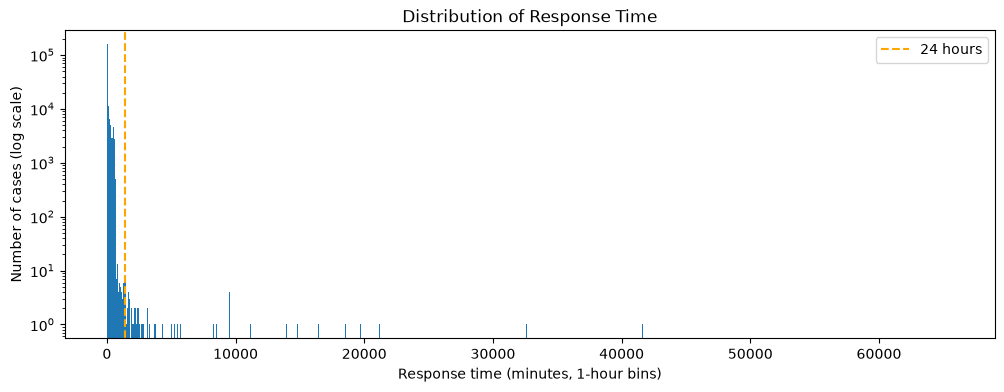

,Response Minutes
count,216406.000000
mean,80.393505
std,258.563459
min,0.766667
25%,9.200000
50%,21.833333
75%,70.516667
max,65653.433333


In [17]:
print("Cases waiting more than 24 hours:", (cases["response_minutes"] > 24 * 60).sum())

# Response time histogram with 1-hour bins
plt.figure(figsize=(12, 4))
plt.hist(cases["response_minutes"], bins=np.arange(0, cases["response_minutes"].max() + 60, 60))
plt.axvline(24 * 60, color="orange", linestyle="--", label="24 hours")
plt.yscale("log")
plt.xlabel("Response time (minutes, 1-hour bins)")
plt.ylabel("Number of cases (log scale)")
plt.title("Distribution of Response Time")
plt.legend()
plt.show()

pd.DataFrame({"Response Minutes": cases["response_minutes"].describe()})

Most cases get a reply within a few hours. Only 73 cases wait more than 24 hours, and they are spread thinly over a long tail up to about 45 days.

- These very late replies are unlikely to be a normal first response to the customer.
- They are only about 0.03% of the cases, but they pull the mean up.
- We remove cases that wait more than 24 hours, then plot the distribution again.

Cases before removing long waits: 216406
Cases after removing long waits: 216333


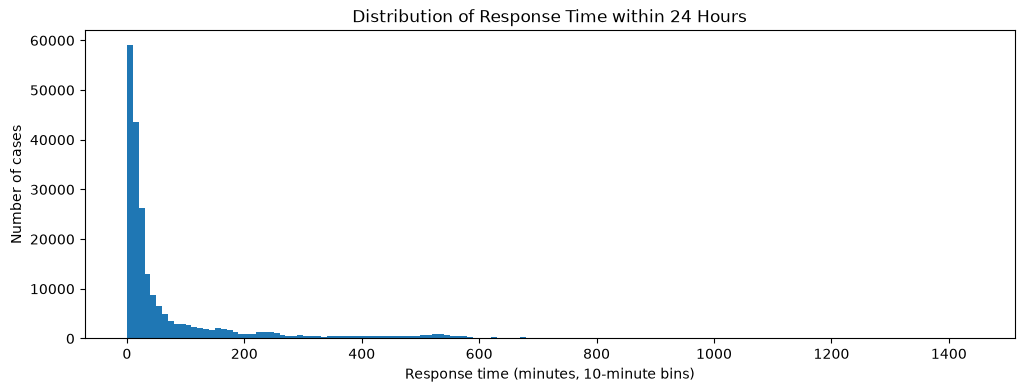

,Response Minutes
count,216333.000000
mean,78.091285
std,132.221079
min,0.766667
25%,9.200000
50%,21.816667
75%,70.383333
max,1435.466667


In [18]:
print("Cases before removing long waits:", cases.shape[0])
# Remove cases that waited more than 24 hours
cases = cases[cases["response_minutes"] <= 24 * 60].copy()
print("Cases after removing long waits:", cases.shape[0])

# Plot again with 10-minute bins
plt.figure(figsize=(12, 4))
plt.hist(cases["response_minutes"], bins=np.arange(0, 24 * 60 + 10, 10))
plt.xlabel("Response time (minutes, 10-minute bins)")
plt.ylabel("Number of cases")
plt.title("Distribution of Response Time within 24 Hours")
plt.show()

pd.DataFrame({"Response Minutes": cases["response_minutes"].describe()})

#### Select Columns and Save

We keep the columns needed by the three research questions and give them clear names. Each row of `cases.pkl` is one case.

- `case_id`: the ID of the customer tweet. It is unique for each case.
- `brand`: the support account, `AmazonHelp` or `AppleSupport`.
- `customer_id`: the ID of the customer.
- `customer_text`: the text of the customer tweet.
- `created_at`: the time when the customer tweet was posted (UTC).
- `is_first_tweet`: whether the customer tweet starts a conversation.
- `reply_tweet_id`: the ID of the first brand reply.
- `reply_text`: the text of the first brand reply.
- `reply_at`: the time when the first brand reply was posted (UTC).
- `response_minutes`: the waiting time in minutes, from `created_at` to `reply_at`.

In [19]:
# Old column name -> new column name
new_names = {
    "tweet_id_customer": "case_id",
    "related_brand_customer": "brand",
    "author_id_customer": "customer_id",
    "text_customer": "customer_text",
    "created_at_customer": "created_at",
    "is_first_tweet": "is_first_tweet",
    "tweet_id_reply": "reply_tweet_id",
    "text_reply": "reply_text",
    "created_at_reply": "reply_at",
    "response_minutes": "response_minutes",
}
# Keep only these columns, rename them and sort by time
cases = cases[list(new_names.keys())].rename(columns=new_names)
cases = cases.sort_values("created_at").reset_index(drop=True)

# Save for RQ1, RQ2 and RQ3
cases.to_pickle("./data/cases.pkl")
print("Saved", cases.shape[0], "cases to ./data/cases.pkl")
cases.head()

Saved 216333 cases to ./data/cases.pkl


,case_id,brand,customer_id,customer_text,created_at,is_first_tweet,reply_tweet_id,reply_text,reply_at,response_minutes
0,193661,AppleSupport,161535,@AppleSupport Yes I’m able to open safari but ...,2017-10-04 00:03:07+00:00,True,193660,@161535 Understood! Can you tell us the versio...,2017-10-04 00:59:51+00:00,56.733333
1,1286995,AmazonHelp,421025,"@AmazonHelp I can't explain in 140 c, that's w...",2017-10-04 00:04:13+00:00,False,1286994,@421025 You can send us a direct message if yo...,2017-10-04 00:12:31+00:00,8.300000
2,243032,AppleSupport,173714,Apple Podcast is not played continuously on #i...,2017-10-04 00:07:40+00:00,True,243030,@173714 Let's see if we can keep your podcasts...,2017-10-04 00:36:31+00:00,28.850000
3,387506,AppleSupport,207722,@AppleSupport I did that yesterday.,2017-10-04 00:15:29+00:00,False,387504,"@207722 Which iPhone do you have, and what's t...",2017-10-04 00:37:54+00:00,22.416667
4,1286993,AmazonHelp,421025,"@AmazonHelp I found the email, never mind.",2017-10-04 00:24:40+00:00,False,1286992,@421025 No problem! Anytime you need assistanc...,2017-10-04 00:33:30+00:00,8.833333


### 2. Effect of Posting Time

#### Convert to Local Time

`created_at` is stored in UTC. We convert it to US Eastern Time so that "morning" and "night" match local hours. We do not know each customer's real time zone, so we assume most customers are in the US.

In [20]:
cases["local_time"] = cases["created_at"].dt.tz_convert("America/New_York")

cases["hour"] = cases["local_time"].dt.hour            # hour of day, 0-23
cases["weekday"] = cases["local_time"].dt.day_name()   # Monday, Tuesday, ...

# Check the new columns
cases[["created_at", "local_time", "hour", "weekday", "response_minutes"]].head()

,created_at,local_time,hour,weekday,response_minutes
0,2017-10-04 00:03:07+00:00,2017-10-03 20:03:07-04:00,20,Tuesday,56.733333
1,2017-10-04 00:04:13+00:00,2017-10-03 20:04:13-04:00,20,Tuesday,8.300000
2,2017-10-04 00:07:40+00:00,2017-10-03 20:07:40-04:00,20,Tuesday,28.850000
3,2017-10-04 00:15:29+00:00,2017-10-03 20:15:29-04:00,20,Tuesday,22.416667
4,2017-10-04 00:24:40+00:00,2017-10-03 20:24:40-04:00,20,Tuesday,8.833333


#### Response Time by Hour

We use the median response time because a few very long waits would pull the mean up. The y-axis uses a log scale so both brands fit on one chart.

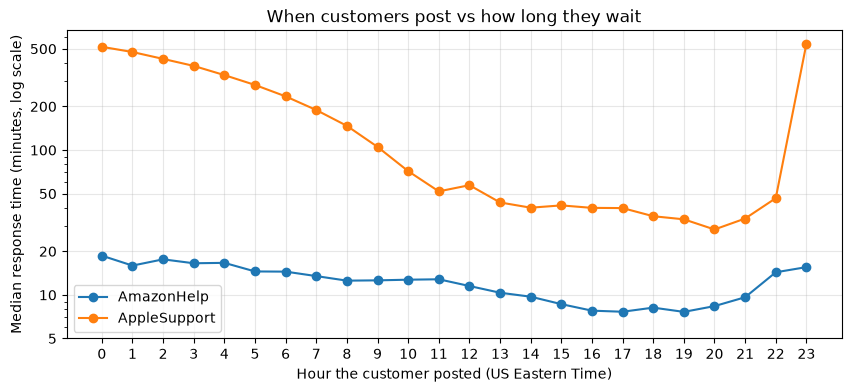

In [21]:
# Median response time for each (hour, brand) pair; median is robust to very long waits
hourly = cases.groupby(["hour", "brand"])["response_minutes"].median().unstack()

plt.figure(figsize=(10, 4))
for brand in hourly.columns:
    plt.plot(hourly.index, hourly[brand], marker="o", label=brand)
plt.yscale("log")   # log scale so both brands fit on one chart
plt.yticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])  # readable tick labels
plt.xticks(range(24))
plt.xlabel("Hour the customer posted (US Eastern Time)")
plt.ylabel("Median response time (minutes, log scale)")
plt.title("When customers post vs how long they wait")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Response Time by Time of Day

We group the 24 hours into four buckets: Morning (6-12), Afternoon (12-18), Evening (18-24) and Night (0-6).

In [22]:
def time_of_day(h):
    """Map an hour (0-23) to one of four time-of-day buckets."""
    if 6 <= h < 12:
        return "Morning (6-12)"
    elif 12 <= h < 18:
        return "Afternoon (12-18)"
    elif 18 <= h < 24:
        return "Evening (18-24)"
    else:
        return "Night (0-6)"

cases["time_of_day"] = cases["hour"].apply(time_of_day)
time_order = ["Morning (6-12)", "Afternoon (12-18)", "Evening (18-24)", "Night (0-6)"]

# Number of cases, median and mean wait for each brand and time bucket, in chronological order
time_summary = cases.groupby(["brand", "time_of_day"])["response_minutes"].agg(["count", "median", "mean"]).round(1)
time_summary.reindex(time_order, level="time_of_day")

count  median   mean
brand        time_of_day                            
AmazonHelp   Morning (6-12)     35545    13.1   18.3
             Afternoon (12-18)  31782     9.3   15.6
             Evening (18-24)    20578    10.0   16.5
             Night (0-6)        27271    16.5   23.3
AppleSupport Morning (6-12)     23622   117.1  131.4
             Afternoon (12-18)  36491    44.1   69.5
             Evening (18-24)    27849    41.5  124.5
             Night (0-6)        13195   437.8  429.5

#### Response Time by Weekday

In [23]:
# Median response time by weekday, in calendar order
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
cases.groupby(["weekday", "brand"])["response_minutes"].median().unstack().reindex(days).round(1)

brand,AmazonHelp,AppleSupport
weekday,,
Monday,13.3,47.8
Tuesday,12.4,41.0
Wednesday,11.6,40.1
Thursday,11.4,64.8
Friday,11.3,158.6
Saturday,12.0,167.2
Sunday,12.6,95.3


Apple is much slower from Thursday to Saturday. The iOS 11.1 keyboard bug (Oct 31 - Nov 9, 2017) made Apple slow for about ten days, so we check whether the weekday pattern is only caused by the bug.

In [24]:
# Check whether Apple's weekday pattern is driven by the iOS 11.1 bug period (Oct 31 - Nov 9, 2017)
apple = cases[cases["brand"] == "AppleSupport"]
in_bug = (apple["local_time"] >= "2017-10-31") & (apple["local_time"] < "2017-11-10")

pd.DataFrame({
    "All days": apple.groupby("weekday")["response_minutes"].median(),
    "Without bug period": apple[~in_bug].groupby("weekday")["response_minutes"].median(),
}).reindex(days).round(1)

,All days,Without bug period
weekday,,
Monday,47.8,24.2
Tuesday,41.0,28.8
Wednesday,40.1,35.9
Thursday,64.8,54.0
Friday,158.6,111.4
Saturday,167.2,117.2
Sunday,95.3,52.1


#### Findings: Posting Time

- **AmazonHelp replies fast at every hour.** The median wait stays between about 8 and 19 minutes all day. Night posts (0-6) wait a little longer (16.5 min) than afternoon posts (9.3 min), but the gap is small. Amazon seems to staff support around the clock.
- **AppleSupport depends strongly on posting time.** Afternoon and evening posts wait about 42-44 minutes (median), but night posts wait about 437 minutes (over 7 hours), roughly **10 times longer**.
- The Apple curve jumps at **23:00 ET** and slowly falls until about 11:00. This suggests Apple's support team mostly stops replying late at night, so these tweets wait until the next morning.
- By weekday, Amazon is flat (11-13 min). Apple is slower from Thursday to Saturday (65-168 min) than from Monday to Wednesday (40-48 min). Part of this comes from the iOS 11.1 bug period, which made Apple slower overall. But even after removing those days, Friday and Saturday are still much slower (about 115 min vs 24-36 min), so the weekly pattern is not only caused by the bug.
- The data covers only about 9 weeks, so each weekday has only about 9 days. One very busy day can move a weekday's median a lot.

**Limitation:** we do not know each customer's real time zone, so we use US Eastern Time for everyone.

### 3. Effect of Words

#### Clean the Text

We remove @mentions and links, because they are not the customer's own words and could confuse the word matching.

In [25]:
# Remove @mentions and links so they don't affect word matching
text = (cases["customer_text"]
        .str.replace(r"@\w+", "", regex=True)
        .str.replace(r"http\S+", "", regex=True))

# Compare one tweet before and after cleaning
print("Before:", cases["customer_text"].iloc[0])
print("After: ", text.iloc[0])

Before: @AppleSupport Yes I’m able to open safari but the problem is that it’s gets faded everytime not only safari all apps.
After:   Yes I’m able to open safari but the problem is that it’s gets faded everytime not only safari all apps.


#### Polite and Rude Word Lists

We flag polite and rude tweets with **regular expressions**. The word lists were built in rounds: we started from common words, then read random tweets that were *not* flagged and added the polite or rude words we had missed (for example *could you*, *hello*, *rubbish*, *scam*).

Pattern notes:
- `\b` is a word boundary, so `hate` does not match "whatever" or "hateful".
- `\w*` allows extra letters, so `\w*fuck\w*` matches "fucking" and "motherfucker".
- `thank(?:s|you|u)?` matches "thank", "thanks", "thankyou", "thanku" but **not** "Thanksgiving".

In [26]:
# Polite words: requests, thanks, apologies and greetings
polite_words = [
    "please", "pls", "plz", r"thank(?:s|you|u)?", "thx", "ty", r"appreciate\w*", "grateful",
    "kindly", "sorry", "excuse me", "could you", "would you", "regards", "dear", "hi", "hello",
    r"good (?:morning|afternoon|evening)",
]

# Rude words: swearing, insults and strong angry judgments
rude_words = [
    r"\w*fuck\w*", r"fuk\w*", r"\w*shit\w*", r"damn\w*", r"goddam\w*", "wtf", r"crap\w*", "hell",
    "ass", r"asshole\w*", "pissed", r"screw(?:ed|s)?", "stupid", r"idiot\w*", "dumb", "ridiculous",
    "worst", "terrible", "awful", "horrible", "useless", "pathetic", "rubbish", "garbage", "trash",
    "joke", "hate", r"sucks?", "annoying", "unacceptable", "disgusting", "incompetent", "clueless",
    "lame", r"scam\w*", r"cheat\w*", r"fraud\w*", r"liars?",
]

# Join each list into one pattern: \b(?:word1|word2|...)\b
polite_pattern = r"\b(?:" + "|".join(polite_words) + r")\b"
rude_pattern = r"\b(?:" + "|".join(rude_words) + r")\b"

cases["is_polite"] = text.str.contains(polite_pattern, case=False, regex=True)
cases["is_rude"] = text.str.contains(rude_pattern, case=False, regex=True)
cases["has_exclaim"] = text.str.contains(r"!{2,}", regex=True)   # two or more "!" in a row

#### Shouting (All Caps)

A word in capital letters can mean shouting, but many all-caps words are just brand names or acronyms. We list the most common all-caps words to see which ones are not shouting.

In [27]:
# Most common all-caps words (4+ letters)
text.str.findall(r"\b[A-Z]{4,}\b").explode().value_counts().head()

customer_text
THIS    1068
ASAP     910
USPS     790
AMZL     711
HELP     637
Name: count, dtype: int64

Words such as USPS, AMZL (Amazon Logistics), ASAP and IPHONE are names or acronyms, not shouting. We exclude them, and we count a tweet as **shouting** only if it has **at least two** other all-caps words. One capital word may just be emphasis; several in a row read as shouting.

In [28]:
# All-caps words that are brand names or acronyms, not shouting
not_shouting = {
    "ASAP", "USPS", "AMZL", "AMZN", "AMAZON", "APPLE", "IPHONE", "IPAD", "IPOD", "IMAC", "MACBOOK",
    "ICLOUD", "ITUNES", "PRIME", "KINDLE", "ALEXA", "ECHO", "FEDEX", "HDMI", "WIFI",
}

def is_shouting(s):
    """True if the tweet has at least two all-caps words that are not names or acronyms."""
    caps_words = re.findall(r"\b[A-Z]{4,}\b", s)
    caps_words = [w for w in caps_words if w not in not_shouting]
    return len(caps_words) >= 2

cases["is_shouting"] = text.apply(is_shouting)

# Share of tweets with each feature
cases[["is_polite", "is_rude", "has_exclaim", "is_shouting"]].mean().round(3)

is_polite      0.177
is_rude        0.147
has_exclaim    0.037
is_shouting    0.022
dtype: float64

#### Tone Groups

A tweet can contain both polite and rude words (e.g. *"please fix this shit"*). We put each tweet into one of four groups:

- **Polite:** polite words, no rude words
- **Rude:** rude words, no polite words
- **Mixed:** both
- **Neutral:** neither

In [29]:
def tone_group(polite, rude):
    """Combine the polite and rude flags into one tone group."""
    if polite and rude:
        return "Mixed"
    elif polite:
        return "Polite"
    elif rude:
        return "Rude"
    else:
        return "Neutral"

cases["tone"] = [tone_group(p, r) for p, r in zip(cases["is_polite"], cases["is_rude"])]
tone_order = ["Polite", "Neutral", "Mixed", "Rude"]

cases["tone"].value_counts(normalize=True).reindex(tone_order).round(3)

tone
Polite     0.159
Neutral    0.694
Mixed      0.018
Rude       0.129
Name: proportion, dtype: float64

#### Manual Check of the Labels

Regular expressions match words, not meaning. To measure how often the labels are right, we drew **50 random tweets flagged polite and 50 flagged rude** and read each one by hand. A label is counted as correct if the tweet is really polite (or really rude/angry). The labels are saved in `rq1_manual_check.csv`.

The sample was drawn with:
```python
cases.loc[cases["is_polite"]].sample(50, random_state=random_seed)
cases.loc[cases["is_rude"]].sample(50, random_state=random_seed)
```

In [30]:
# Load the hand labels and attach the tweet text and current flags
check = pd.read_csv("./data/rq1_manual_check.csv")
check = check.merge(cases[["case_id", "customer_text", "is_polite", "is_rude", "tone"]], on="case_id")

# Keep tweets still flagged by the current patterns (one "Thanksgiving" tweet was fixed after this check)
still_flagged = np.where(check["flag"] == "is_polite", check["is_polite"], check["is_rude"])
check = check[still_flagged]

print("Share of labels that are correct:")
print(check.groupby("flag")["correct"].agg(["count", "mean"]).round(2))

Share of labels that are correct:
           count  mean
flag                  
is_polite     49  0.69
is_rude       50  0.96


In [31]:
# Most polite-label errors are sarcastic "thanks"; do the tone groups help?
print("Correct rate for the 'Polite' tone group (polite words, no rude words):")
polite_check = check[(check["flag"] == "is_polite") & (check["tone"] == "Polite")]
print(round(polite_check["correct"].mean(), 2), f"({len(polite_check)} tweets)")

print("\nExamples of wrong polite labels:")
for _, row in check[(check["flag"] == "is_polite") & (check["correct"] == 0)].head().iterrows():
    print(f"- [{row['note']}] {row['customer_text'][:120]}")

Correct rate for the 'Polite' tone group (polite words, no rude words):
0.77 (43 tweets)

Examples of wrong polite labels:
- [sarcastic thanks] @115830 thanks for ruining the Christmas presents I ordered for family and not sending them in an amazon box and just wh
- [sarcastic thanks] Thanks @115858 for deleting all my numbers files from all my devices and the cloud with the latest update 🤬 https://t.co
- [sarcastic thanks, swearing] @AppleSupport this new update is bullshit!!! Thanks for fucking up my phone! AGAIN!!!
- [angry, says hate] hate. hate. hate ios 11. @AppleSupport MY DANG BATTERY DIES FASTER. please fix it smh.
- [sarcastic thanks for nothing] Thanks for nothing @115821 you guys didn’t deliver today due to amazon locker being filled. Called cust service and nobo


#### Response Time by Wording

In [32]:
# Median wait for each tone group
tone_table = cases.groupby(["brand", "tone"])["response_minutes"].agg(["count", "median"]).round(1)
tone_table.reindex(tone_order, level="tone")

count  median
brand        tone                  
AmazonHelp   Polite   19314    12.4
             Neutral  83551    11.8
             Mixed     1229    13.2
             Rude     11082    12.7
AppleSupport Polite   15127    75.0
             Neutral  66538    65.9
             Mixed     2655    95.1
             Rude     16837    94.3

In [33]:
# For "!!" and shouting, compare the median wait of tweets with vs without the feature
rows = []
for f in ["has_exclaim", "is_shouting"]:
    medians = cases.groupby(["brand", f])["response_minutes"].median().unstack()
    for brand in medians.index:
        rows.append({"feature": f, "brand": brand,
                     "without": medians.loc[brand, False], "with": medians.loc[brand, True]})

style = pd.DataFrame(rows)
style["difference"] = style["with"] - style["without"]   # positive = waits longer
style.round(1)

,feature,brand,without,with,difference
0,has_exclaim,AmazonHelp,12.0,11.4,-0.6
1,has_exclaim,AppleSupport,70.5,91.0,20.5
2,is_shouting,AmazonHelp,12.0,11.7,-0.3
3,is_shouting,AppleSupport,70.7,95.8,25.2


#### Sentiment with VADER

Word lists cannot read context: *"not terrible"* is positive, but our rude pattern flags it, and sarcasm fools the polite list. As a second method we use **VADER**, a sentiment tool built for social media. It handles negation, capital letters and "!!", and gives each tweet a score from -1 (most negative) to +1 (most positive).

VADER measures **sentiment**, not **politeness**. For example, *"sorry to bother you"* is polite but gets a negative score because of "sorry". So we use it as a check on the rude/negative side, not as a replacement for the polite list.

In [34]:
analyzer = SentimentIntensityAnalyzer()

# A few examples
for s in ["This is not terrible", "iOS 11 sucks!!", "sorry to bother you", "Thanks for nothing"]:
    print(f"{s:25} {analyzer.polarity_scores(s)['compound']:+.2f}")

This is not terrible      +0.37
iOS 11 sucks!!            -0.47
sorry to bother you       -0.40
Thanks for nothing        +0.44


In [35]:
# Compound score from -1 (most negative) to +1 (most positive); handles negation, caps and "!!"
cases["sentiment"] = text.apply(lambda s: analyzer.polarity_scores(s)["compound"])

# Standard VADER thresholds: below -0.05 negative, above 0.05 positive
vader_order = ["Negative", "Neutral", "Positive"]
cases["tone_vader"] = pd.cut(cases["sentiment"], bins=[-1.01, -0.05, 0.05, 1.01], labels=vader_order)

print(cases["tone_vader"].value_counts(normalize=True).reindex(vader_order).round(3))
cases.groupby(["brand", "tone_vader"], observed=True)["response_minutes"].median().unstack().round(1)

tone_vader
Negative    0.384
Neutral     0.266
Positive    0.350
Name: proportion, dtype: float64


tone_vader,Negative,Neutral,Positive
brand,,,
AmazonHelp,11.9,11.8,12.2
AppleSupport,80.3,67.3,65.5


#### Is It the Wording or the Time?

Rude tweets may cluster at night or during the iOS bug, when Apple is slow anyway. If so, the wording gap above is partly a **time effect**, not a wording effect (time is a *confounder*). First we check whether rude tweets really are posted at different times.

In [36]:
apple = cases[cases["brand"] == "AppleSupport"]
in_bug = (apple["local_time"] >= "2017-10-31") & (apple["local_time"] < "2017-11-10")

print("Share of rude tweets (Apple) during the bug:", round(apple.loc[in_bug, "is_rude"].mean(), 3))
print("Share of rude tweets (Apple) outside the bug:", round(apple.loc[~in_bug, "is_rude"].mean(), 3))
print()
print("Share of rude tweets (Apple) by time of day:")
print(apple.groupby("time_of_day")["is_rude"].mean().reindex(time_order).round(3))

Share of rude tweets (Apple) during the bug: 0.25
Share of rude tweets (Apple) outside the bug: 0.17

Share of rude tweets (Apple) by time of day:
time_of_day
Morning (6-12)       0.174
Afternoon (12-18)    0.182
Evening (18-24)      0.208
Night (0-6)          0.223
Name: is_rude, dtype: float64


Then we compare tone groups **within the same time of day**, outside the bug period.

In [37]:
# Median wait by tone, within each time of day (Apple, outside the bug period)
apple_normal = apple[~in_bug]
within_time = (apple_normal.groupby(["time_of_day", "tone"])["response_minutes"]
               .median().unstack().reindex(index=time_order, columns=tone_order))
within_time.round(1)

tone,Polite,Neutral,Mixed,Rude
time_of_day,,,,
Morning (6-12),97.8,91.6,107.9,106.6
Afternoon (12-18),30.7,31.4,32.9,33.0
Evening (18-24),21.8,21.0,33.8,29.4
Night (0-6),401.4,415.6,419.2,433.1


#### Regression: Wording Effect After Controlling for Time

The table above controls for time of day only roughly (4 buckets, one brand, bug days dropped). A regression lets us control for **the exact hour and the exact date** at the same time, and estimate all wording features together.

For each brand we fit:

$$\log(\text{response minutes}) = \text{wording features} + \text{hour of day} + \text{date}$$

- We use the **log** of response time because waits are very skewed; a coefficient $b$ then means the wait changes by about $(e^b - 1) \times 100\%$.
- **Hour** and **date** enter as categories (one dummy per hour and per day), so busy days such as the iOS bug or Black Friday are accounted for.
- Standard errors are robust to unequal variance (HC1).

In [38]:
cases["log_minutes"] = np.log(cases["response_minutes"])
cases["date"] = cases["local_time"].dt.date.astype(str)
cases["negative_vader"] = cases["sentiment"] < -0.05

features = ["is_polite", "is_rude", "has_exclaim", "is_shouting", "negative_vader"]
formula = "log_minutes ~ " + " + ".join(features) + " + C(hour) + C(date)"

results = []
for brand, group in cases.groupby("brand"):
    model = smf.ols(formula, data=group).fit(cov_type="HC1")
    for f in features:
        name = f + "[T.True]"
        low, high = model.conf_int().loc[name]
        results.append({
            "brand": brand,
            "feature": f,
            "effect_%": (np.exp(model.params[name]) - 1) * 100,   # % change in wait
            "ci_low_%": (np.exp(low) - 1) * 100,
            "ci_high_%": (np.exp(high) - 1) * 100,
            "p_value": model.pvalues[name],
        })

effects = pd.DataFrame(results)
effects.round(3)

,brand,feature,effect_%,ci_low_%,ci_high_%,p_value
0,AmazonHelp,is_polite,1.450,0.155,2.762,0.028
1,AmazonHelp,is_rude,4.165,2.491,5.867,0.000
2,AmazonHelp,has_exclaim,-2.641,-5.341,0.135,0.062
3,AmazonHelp,is_shouting,3.347,-0.415,7.250,0.082
4,AmazonHelp,negative_vader,-1.050,-2.089,0.000,0.050
5,AppleSupport,is_polite,-0.496,-1.506,0.524,0.339
6,AppleSupport,is_rude,1.021,-0.067,2.121,0.066
7,AppleSupport,has_exclaim,-1.199,-3.049,0.686,0.211
8,AppleSupport,is_shouting,2.642,0.174,5.171,0.036
9,AppleSupport,negative_vader,0.414,-0.447,1.283,0.347


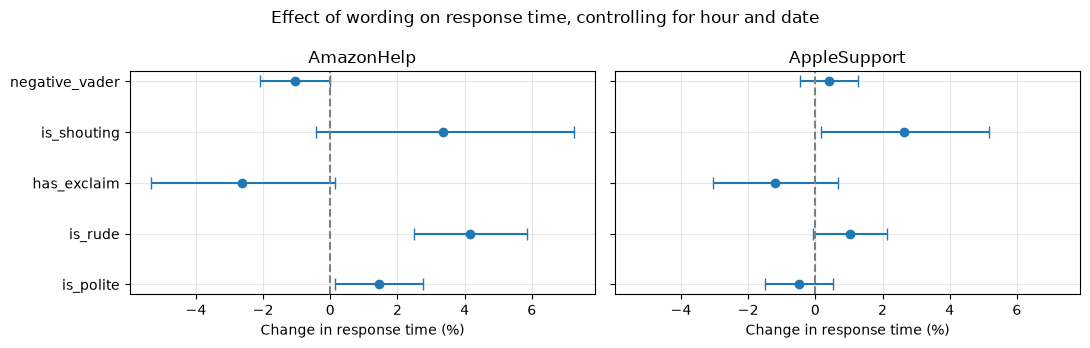

In [39]:
# Plot the estimated effects with 95% confidence intervals
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True, sharey=True)  # same x-axis so brands are comparable
for ax, (brand, group) in zip(axes, effects.groupby("brand")):
    y = range(len(group))
    ax.errorbar(group["effect_%"], y,
                xerr=[group["effect_%"] - group["ci_low_%"], group["ci_high_%"] - group["effect_%"]],
                fmt="o", capsize=4)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(list(y))
    ax.set_yticklabels(group["feature"])
    ax.set_title(brand)
    ax.set_xlabel("Change in response time (%)")
    ax.grid(alpha=0.3)
plt.suptitle("Effect of wording on response time, controlling for hour and date")
plt.tight_layout()
plt.show()

#### Sensitivity Check: Splitting Out "Thanks"

The manual check showed that most wrong polite labels are **sarcastic "thanks"** (*"Thanks for ruining my presents"*), and we could not find a simple rule that detects sarcasm reliably. So instead we ask: **does sarcasm change our conclusion?**

We split the polite words into two groups and put both into the regression:

- `has_thanks`: tweets with *thanks / thx / ty*, where most of the sarcasm is
- `is_polite_other`: tweets with any other polite word (*please, could you, hi, dear, ...*)

We also control for `is_first_tweet` (whether the tweet starts a conversation), because "thanks" often appears in the last tweet of a conversation.

In [40]:
# Split the polite words: "thanks" words vs all other polite words
thanks_words = [r"thank(?:s|you|u)?", "thx", "ty"]
other_polite_words = [w for w in polite_words if w not in thanks_words]

cases["has_thanks"] = text.str.contains(r"\b(?:" + "|".join(thanks_words) + r")\b", case=False, regex=True)
cases["is_polite_other"] = text.str.contains(r"\b(?:" + "|".join(other_polite_words) + r")\b", case=False, regex=True)

print(cases[["has_thanks", "is_polite_other"]].mean().round(3))
print()
print("Share of tweets that start a conversation:")
print(cases.groupby("has_thanks")["is_first_tweet"].mean().round(3))

has_thanks         0.061
is_polite_other    0.126
dtype: float64

Share of tweets that start a conversation:
has_thanks
False    0.614
True     0.450
Name: is_first_tweet, dtype: float64


In [41]:
# Same regression as before, with the polite words split and a control for conversation start
features_split = ["is_polite_other", "has_thanks", "is_rude", "has_exclaim", "is_shouting"]
formula_split = "log_minutes ~ " + " + ".join(features_split) + " + is_first_tweet + C(hour) + C(date)"

results = []
for brand, group in cases.groupby("brand"):
    model = smf.ols(formula_split, data=group).fit(cov_type="HC1")
    median_wait = group["response_minutes"].median()
    for f in features_split:
        name = f + "[T.True]"
        low, high = model.conf_int().loc[name]
        effect = np.exp(model.params[name]) - 1
        results.append({
            "brand": brand,
            "feature": f,
            "effect_%": effect * 100,
            "ci_low_%": (np.exp(low) - 1) * 100,
            "ci_high_%": (np.exp(high) - 1) * 100,
            "p_value": model.pvalues[name],
            "approx_minutes": effect * median_wait,   # effect in minutes at the brand's median wait
        })

effects_split = pd.DataFrame(results)
effects_split.round(3)

,brand,feature,effect_%,ci_low_%,ci_high_%,p_value,approx_minutes
0,AmazonHelp,is_polite_other,12.007,10.407,13.629,0.000,1.439
1,AmazonHelp,has_thanks,-16.365,-18.081,-14.613,0.000,-1.961
2,AmazonHelp,is_rude,3.944,2.338,5.575,0.000,0.473
3,AmazonHelp,has_exclaim,-1.818,-4.535,0.977,0.200,-0.218
4,AmazonHelp,is_shouting,3.116,-0.625,6.998,0.104,0.373
5,AppleSupport,is_polite_other,0.912,-0.269,2.107,0.131,0.649
6,AppleSupport,has_thanks,-3.048,-4.606,-1.465,0.000,-2.170
7,AppleSupport,is_rude,0.280,-0.714,1.284,0.583,0.199
8,AppleSupport,has_exclaim,-1.562,-3.405,0.315,0.102,-1.112
9,AppleSupport,is_shouting,2.009,-0.445,4.523,0.109,1.430


Splitting the polite words reveals something the combined label hid. For **AmazonHelp**, the two kinds of polite words move in **opposite directions**: tweets with "thanks" are answered about 16% faster, while tweets with other polite words (*please, could you, ...*) wait about 12% longer. In the combined `is_polite` label these two effects cancel out. For **AppleSupport**, both effects are small (-3% for "thanks" and +1% for other polite words, the latter not significant).

One possible reason (not tested here) is that "please / could you" tweets often ask for something new that needs checking, while many "thanks" tweets close a conversation and only need a short reply. In minutes, all these effects are about 2 minutes or less, much smaller than the posting-time effect for Apple (hundreds of minutes).

### Findings: Wording

- **How common:** 18% of tweets contain polite words, 15% rude words, 4% have "!!" and 2% are shouting. In tone groups: 16% Polite, 13% Rude, 2% Mixed, 69% Neutral.
- **How reliable are the labels?** In the manual check, **96%** of rude labels were correct (48 of 50), but only **69%** of polite labels (34 of 49). Most polite errors are **sarcastic "thanks"** (*"Thanks for ruining my presents"*). Using the Polite tone group (no rude words) raises this to 77%. VADER is fooled by sarcasm too (*"Thanks for nothing"* scores +0.44). So our results about rude wording are more trustworthy than our results about polite wording.
- **At first glance:** AmazonHelp waits are the same for every tone (11.8-13.2 min median). AppleSupport looks slower for rude tweets (94 min) than for neutral (67 min) or polite (75 min) ones, and also for "!!" (+20 min) and shouting (+25 min).
- **But rude tweets are posted at different times.** For Apple, 25% of tweets are rude during the iOS 11.1 bug vs 17% outside it, and 22% at night vs 17% in the morning. These are exactly the times when Apple is slow anyway.
- **Within the same time of day** (outside the bug), the gap mostly disappears: in the afternoon, polite, neutral and rude tweets wait 31, 31 and 33 minutes.
- **The regression confirms this.** After controlling for the exact hour and date, every wording effect in this main regression is within about **±5%**. For Apple, rude wording changes the wait by +1.0% (95% CI -0.1% to +2.1%, not significant) and polite wording by -0.5% (not significant). For Amazon, rude tweets wait 4% longer (significant, but only about half a minute on a 12-minute wait).
- **Sensitivity check (splitting out "thanks").** Because sarcastic "thanks" makes the polite label noisy, we split polite words into "thanks" words and other polite words. For Amazon this reveals two opposite effects that cancelled out in the combined label: "thanks" tweets are answered about 16% faster (about 2 minutes), while "please / could you" tweets wait about 12% longer (about 1.4 minutes). For Apple both are small (-3% and +1%). The rude effect does not change (Amazon +4%, Apple +0.3%, not significant), so sarcasm does not affect our conclusion about rude wording.

## RQ1 Summary

**Answer to RQ1: when a customer posts matters much more than how they write.**

| | Posting time | Wording (sensitivity-check regression, controlling for time) |
|---|---|---|
| **AmazonHelp** | Small effect: 8-19 min median at every hour | Small: rude +4%; "please"-type words +12%; "thanks" -16% (each 2 minutes or less) |
| **AppleSupport** | Large effect: night posts wait about 10x longer than afternoon posts (437 vs 44 min); Friday and Saturday are slower | Tiny: rude +0.3% (not significant), "thanks" -3% |

- Rude tweets *look* slower for Apple (94 vs 67 min), but this is because rude tweets are more common at night and during the iOS 11.1 bug, when Apple is slow anyway. Once we compare tweets posted at the same hour on the same day, rude wording makes almost no difference.
- Polite wording has small effects for Amazon, and the direction depends on the kind of polite words: "thanks" tweets are answered a little faster, "please / could you" tweets a little slower. These effects are at most about 2 minutes.
- For the waiting-time estimate in the Prediction step, **posting hour, weekday and date** are useful inputs; the polite/rude words change the estimate by only a few minutes.

**Limitations**
- We do not know each customer's real time zone; we use US Eastern Time for everyone.
- Word lists cannot read sarcasm or context; polite labels in particular are only about 70-77% correct.
- VADER measures sentiment, not politeness, and is also fooled by sarcasm.
- The regression shows association, not causation: rude tweets may differ in other ways (e.g. harder problems), which we cannot observe.

## Influence of Peak Events (RQ2)

## Retrieving Related Cases (RQ3)

## Delivered System